# Student Performance EDA for a County Education Office

This project explores student performance data for 1,200 learners. The analysis examines learner characteristics, score distributions, relationships between attendance, study hours and performance, school-type differences, county-level risk patterns, and factors associated with stronger academic outcomes.

In [1]:
%%writefile generate_data.py

import numpy as np
import pandas as pd

rng = np.random.default_rng(55)

n = 1200

students = pd.DataFrame({
    "student_id": range(1, n + 1),
    "county": rng.choice(
        ["Nairobi", "Kisumu", "Nakuru", "Mombasa", "Nyeri", "Turkana"],
        n
    ),
    "school_type": rng.choice(
        ["Public", "Private"],
        n,
        p=[0.75, 0.25]
    ),
    "gender": rng.choice(
        ["F", "M"],
        n
    ),
    "attendance_rate": rng.beta(
        8,
        2,
        n
    ).round(2),
    "study_hours": rng.gamma(
        2.5,
        2.0,
        n
    ).round(1),
})

base = (
    35
    + 30 * students["attendance_rate"]
    + 2.2 * students["study_hours"]
    + np.where(students["school_type"] == "Private", 6, 0)
)

students["math"] = (
    base + rng.normal(0, 8, n)
).clip(0, 100).round(0)

students["english"] = (
    base + rng.normal(3, 7, n)
).clip(0, 100).round(0)

students["science"] = (
    base + rng.normal(-2, 9, n)
).clip(0, 100).round(0)

students.to_csv(
    "student_performance.csv",
    index=False
)

Overwriting generate_data.py


In [2]:
!python generate_data.py

In [3]:
## Structure

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

students = pd.read_csv("student_performance.csv")

print("Shape:", students.shape)
print("\nFirst five rows:")
display(students.head())

print("\nData types:")
print(students.dtypes)

print("\nMissing values:")
print(students.isna().sum())

print("\nDuplicate rows:", students.duplicated().sum())

Shape: (1200, 9)

First five rows:


,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0



Data types:
student_id           int64
county              object
school_type         object
gender              object
attendance_rate    float64
study_hours        float64
math               float64
english            float64
science            float64
dtype: object

Missing values:
student_id         0
county             0
school_type        0
gender             0
attendance_rate    0
study_hours        0
math               0
english            0
science            0
dtype: int64

Duplicate rows: 0


### Structure Notes

The dataset contains 1,200 rows, where each row represents one student.

The variables are:

- `student_id`: identifier, discrete numerical ID
- `county`: nominal categorical variable
- `school_type`: nominal categorical variable
- `gender`: nominal categorical variable
- `attendance_rate`: continuous numerical variable
- `study_hours`: continuous numerical variable
- `math`: numerical score
- `english`: numerical score
- `science`: numerical score

The dataset should contain no missing values and no duplicate rows. The analysis covers student performance rather than a time series, so there is no date variable.

In [5]:
students["average_score"] = students[
    ["math", "english", "science"]
].mean(axis=1)

students["performance_band"] = pd.cut(
    students["average_score"],
    bins=[-np.inf, 60, 75, np.inf],
    labels=["At Risk", "Meeting", "Exceeding"],
    right=False
)

students[
    ["math", "english", "science", "average_score", "performance_band"]
].head()

,math,english,science,average_score,performance_band
0,81.0,71.0,73.0,75.0,Exceeding
1,100.0,86.0,90.0,92.0,Exceeding
2,82.0,89.0,90.0,87.0,Exceeding
3,83.0,91.0,72.0,82.0,Exceeding
4,76.0,69.0,62.0,69.0,Meeting


In [6]:
## Univariate

In [7]:
numeric_cols = [
    "attendance_rate",
    "study_hours",
    "math",
    "english",
    "science",
    "average_score"
]

univariate_summary = pd.DataFrame({
    "mean": students[numeric_cols].mean(),
    "median": students[numeric_cols].median(),
    "std": students[numeric_cols].std(),
    "Q1": students[numeric_cols].quantile(0.25),
    "Q3": students[numeric_cols].quantile(0.75),
    "IQR": (
        students[numeric_cols].quantile(0.75)
        - students[numeric_cols].quantile(0.25)
    ),
    "skewness": students[numeric_cols].skew()
}).round(2)

univariate_summary

,mean,median,std,Q1,Q3,IQR,skewness
attendance_rate,0.80,0.82,0.12,0.73,0.90,0.17,-0.86
study_hours,5.08,4.50,3.03,2.90,6.70,3.80,1.17
math,71.89,72.00,10.86,65.00,79.00,14.00,0.10
english,74.52,74.00,10.49,67.00,81.00,14.00,0.16
science,69.61,69.00,12.02,61.00,78.00,17.00,0.11
average_score,72.01,71.67,9.11,65.67,77.67,12.00,0.26


In [8]:
categorical_cols = [
    "county",
    "school_type",
    "gender",
    "performance_band"
]

for col in categorical_cols:
    print(f"\n{col.upper()}")
    print("Counts:")
    print(students[col].value_counts())

    print("\nShares:")
    print(
        (students[col].value_counts(normalize=True) * 100)
        .round(1)
        .astype(str) + "%"
    )


COUNTY
Counts:
county
Mombasa    212
Kisumu     208
Nyeri      203
Nakuru     202
Turkana    191
Nairobi    184
Name: count, dtype: int64

Shares:
county
Mombasa    17.7%
Kisumu     17.3%
Nyeri      16.9%
Nakuru     16.8%
Turkana    15.9%
Nairobi    15.3%
Name: proportion, dtype: object

SCHOOL_TYPE
Counts:
school_type
Public     866
Private    334
Name: count, dtype: int64

Shares:
school_type
Public     72.2%
Private    27.8%
Name: proportion, dtype: object

GENDER
Counts:
gender
F    612
M    588
Name: count, dtype: int64

Shares:
gender
F    51.0%
M    49.0%
Name: proportion, dtype: object

PERFORMANCE_BAND
Counts:
performance_band
Meeting      672
Exceeding    429
At Risk       99
Name: count, dtype: int64

Shares:
performance_band
Meeting      56.0%
Exceeding    35.8%
At Risk       8.2%
Name: proportion, dtype: object


In [9]:
q1 = students["study_hours"].quantile(0.25)
q3 = students["study_hours"].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

study_outliers = students[
    (students["study_hours"] < lower_fence)
    | (students["study_hours"] > upper_fence)
]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)
print("Study-hours outliers:", len(study_outliers))

Q1: 2.9
Q3: 6.7
IQR: 3.8000000000000003
Lower fence: -2.8000000000000003
Upper fence: 12.4
Study-hours outliers: 29


In [10]:
## Bivariate

In [11]:
corr_cols = [
    "attendance_rate",
    "study_hours",
    "math",
    "english",
    "science",
    "average_score"
]

correlation_matrix = students[corr_cols].corr().round(3)

correlation_matrix

,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.000,-0.029,0.300,0.327,0.260,0.359
study_hours,-0.029,1.000,0.560,0.624,0.550,0.704
math,0.300,0.560,1.000,0.559,0.459,0.814
english,0.327,0.624,0.559,1.000,0.502,0.827
science,0.260,0.550,0.459,0.502,1.000,0.815
average_score,0.359,0.704,0.814,0.827,0.815,1.000


In [12]:
average_score_corr = (
    correlation_matrix["average_score"]
    .drop("average_score")
    .abs()
    .sort_values(ascending=False)
)

print("Strongest relationships with average_score:")
print(average_score_corr.head(3))

Strongest relationships with average_score:
english    0.827
science    0.815
math       0.814
Name: average_score, dtype: float64


In [13]:
gender_summary = (
    students.groupby("gender")["average_score"]
    .mean()
    .round(2)
)

school_type_summary = (
    students.groupby("school_type")["average_score"]
    .mean()
    .round(2)
)

county_summary = (
    students.groupby("county")["average_score"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

print("Average score by gender:")
print(gender_summary)

print("\nAverage score by school type:")
print(school_type_summary)

print("\nAverage score by county:")
print(county_summary)

Average score by gender:
gender
F    72.10
M    71.91
Name: average_score, dtype: float64

Average score by school type:
school_type
Private    76.01
Public     70.46
Name: average_score, dtype: float64

Average score by county:
county
Kisumu     73.07
Mombasa    72.17
Nairobi    71.96
Nyeri      71.94
Nakuru     71.84
Turkana    70.97
Name: average_score, dtype: float64


In [14]:
at_risk_share = (
    pd.crosstab(
        students["county"],
        students["performance_band"],
        normalize="index"
    ) * 100
).round(1)

print(at_risk_share)

highest_at_risk_county = at_risk_share["At Risk"].idxmax()
highest_at_risk_share = at_risk_share["At Risk"].max()

print(
    f"\nCounty with highest At Risk share: "
    f"{highest_at_risk_county} ({highest_at_risk_share}%)"
)

performance_band  At Risk  Meeting  Exceeding
county                                       
Kisumu                8.2     50.5       41.3
Mombasa               9.0     54.2       36.8
Nairobi               9.2     55.4       35.3
Nakuru                6.4     61.9       31.7
Nyeri                 8.9     54.7       36.5
Turkana               7.9     59.7       32.5

County with highest At Risk share: Nairobi (9.2%)


In [15]:
## Multivariate

In [16]:
students["attendance_band"] = pd.cut(
    students["attendance_rate"],
    bins=[0, 0.70, 0.85, 1.0],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

students["study_quartile"] = pd.qcut(
    students["study_hours"],
    4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

students[
    ["attendance_rate", "attendance_band", "study_hours", "study_quartile"]
].head()

,attendance_rate,attendance_band,study_hours,study_quartile
0,0.77,Medium,6.5,Q3
1,0.97,High,8.5,Q4
2,0.98,High,8.0,Q4
3,0.93,High,6.0,Q3
4,0.67,Low,6.1,Q3


In [17]:
attendance_pivot = pd.pivot_table(
    students,
    index="attendance_band",
    columns="school_type",
    values="average_score",
    aggfunc="mean",
    observed=True
).round(2)

attendance_pivot

school_type,Private,Public
attendance_band,,
Low,71.51,64.94
Medium,75.53,69.80
High,78.99,73.96


In [18]:
study_pivot = pd.pivot_table(
    students,
    index="study_quartile",
    columns="school_type",
    values="average_score",
    aggfunc="mean",
    observed=True
).round(2)

study_pivot

school_type,Private,Public
study_quartile,,
Q1,69.51,63.82
Q2,74.92,67.12
Q3,76.18,71.18
Q4,83.65,80.06


In [19]:
x = students["study_hours"]
y = students["average_score"]

slope, intercept = np.polyfit(x, y, 1)

predicted = slope * x + intercept

ss_res = ((y - predicted) ** 2).sum()
ss_tot = ((y - y.mean()) ** 2).sum()
r2 = 1 - (ss_res / ss_tot)

print(f"Slope: {slope:.2f}")
print(f"Intercept: {intercept:.2f}")
print(f"R²: {r2:.3f}")

Slope: 2.12
Intercept: 61.26
R²: 0.495


### Trend Line Interpretation

The slope shows the average change in `average_score` associated with one additional hour of study.

This relationship is an association, not proof that extra study hours directly cause higher scores.

A limitation is that predictions outside the observed range of study hours may be unreliable because the trend line is based only on the values present in this dataset.

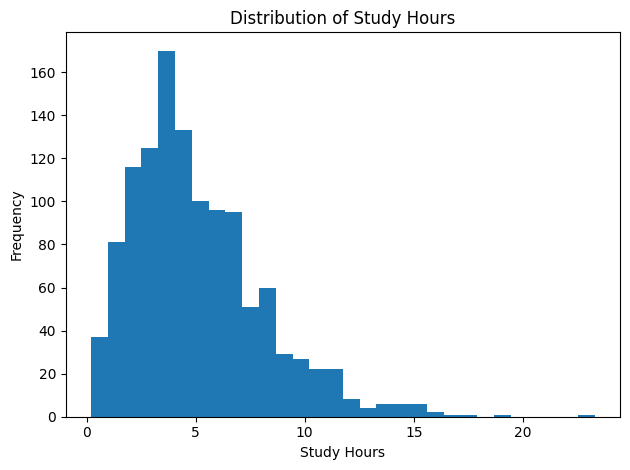

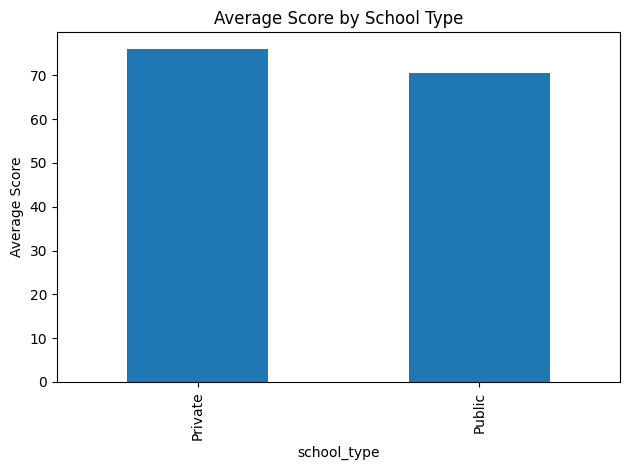

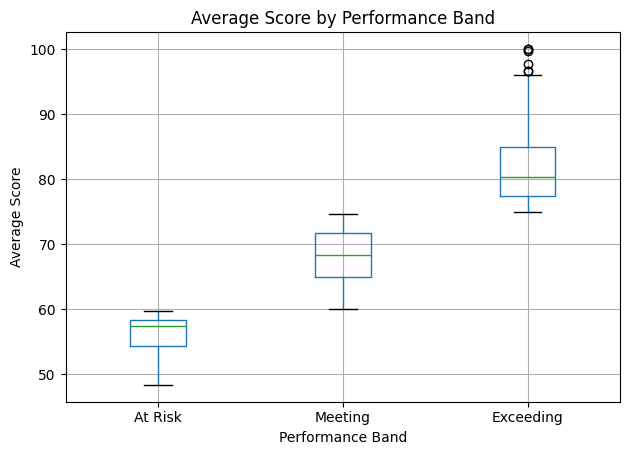

In [20]:
import os

os.makedirs("figures", exist_ok=True)

# 1. Histogram of study hours
ax = students["study_hours"].plot(
    kind="hist",
    bins=30,
    title="Distribution of Study Hours"
)
ax.set_xlabel("Study Hours")
plt.tight_layout()
plt.savefig("figures/study_hours_hist.png")
plt.show()

# 2. Bar chart of average score by school type
ax = (
    students.groupby("school_type")["average_score"]
    .mean()
    .plot(
        kind="bar",
        title="Average Score by School Type"
    )
)
ax.set_ylabel("Average Score")
plt.tight_layout()
plt.savefig("figures/school_type_average_score.png")
plt.show()

# 3. Box plot of average score by performance band
ax = students.boxplot(
    column="average_score",
    by="performance_band"
)
plt.title("Average Score by Performance Band")
plt.suptitle("")
plt.xlabel("Performance Band")
plt.ylabel("Average Score")
plt.tight_layout()
plt.savefig("figures/performance_band_boxplot.png")
plt.show()

### Charts

The following charts support the analysis:

- `figures/study_hours_hist.png` shows the distribution of study hours.
- `figures/school_type_average_score.png` compares average scores between public and private schools.
- `figures/performance_band_boxplot.png` shows the spread of average scores across performance bands.

## Findings

1. Student performance is positively associated with both attendance and study hours. Learners with higher attendance rates and more study time generally achieve higher average scores.

2. Private-school students have higher average scores than public-school students. The school-type gap remains visible when students are compared within similar attendance bands.

3. The school-type difference also remains across study-hour quartiles, suggesting that attendance and study time alone do not fully explain the performance gap.

4. The county analysis shows that the share of At Risk learners varies across counties. The county with the highest At Risk percentage should receive particular attention when learner-support resources are allocated.

5. The three subject scores are strongly related to the overall `average_score`, while attendance and study hours provide useful additional indicators of learner performance.

## Recommendations

1. Prioritise learner-support programmes for students in the At Risk performance band, especially learners with low attendance and low study hours.

2. Direct additional support toward counties and public schools with higher proportions of At Risk learners, while investigating other factors that may explain the remaining school-type performance gap.

## Limitations

This analysis is exploratory and identifies associations rather than causal relationships. The dataset does not include potentially important factors such as household income, teacher quality, class size, school resources or prior academic performance. The trend line between study hours and average score should not be used to make predictions far outside the observed study-hour range. Because the dataset is synthetic and contains no time variable, the findings should not be interpreted as evidence of real changes in student performance over time.

In [21]:
%%writefile requirements.txt
pandas
numpy
matplotlib

Overwriting requirements.txt


In [22]:
%%writefile README.md
# Student Performance EDA for a County Education Office

## Project Summary

This project performs exploratory data analysis on a synthetic student-performance dataset containing 1,200 learners. The analysis examines data structure, score distributions, relationships between attendance, study hours and performance, school-type differences, county-level risk patterns, and factors associated with stronger academic results.

## How to Run

1. Run `python generate_data.py` to create `student_performance.csv`.
2. Open `student_eda.ipynb` in Google Colab or Jupyter Notebook.
3. Run all cells from top to bottom.
4. The notebook creates the required analysis tables and saves charts inside the `figures/` folder.

## Five Key Insights

1. Higher attendance and more study hours are associated with higher average student scores.
2. Private-school students have higher average scores than public-school students.
3. The school-type gap remains visible within attendance bands, so attendance alone does not explain the difference.
4. The school-type gap also persists across study-hour quartiles, suggesting that study time alone does not fully explain the difference.
5. The proportion of At Risk learners varies by county, which can help guide where learner-support resources should be targeted.

## Outputs

The notebook includes:

- Structure analysis
- Univariate analysis
- Bivariate analysis
- Multivariate analysis
- Hypotheses and interpretation
- Correlation matrix
- School-type gap pivot tables
- Trend line with slope and R²
- Findings, Recommendations and Limitations
- At least three saved PNG charts in the `figures/` folder

Overwriting README.md


## Hypotheses

1. Students with higher attendance rates tend to achieve higher average scores.
2. Students who study more hours tend to achieve higher average scores.
3. Private-school students tend to have higher average scores than public-school students, even when comparing learners with similar attendance and study-hour levels.

These patterns show associations in this dataset and do not prove causation.

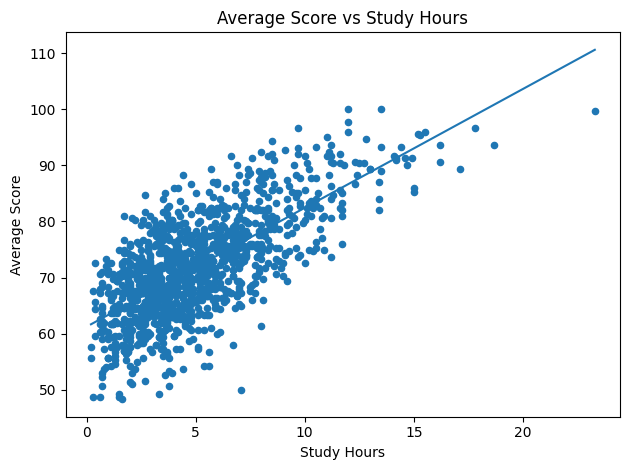

Slope: 2.12
R²: 0.495


In [23]:
x = students["study_hours"]
y = students["average_score"]

slope, intercept = np.polyfit(x, y, 1)
predicted = slope * x + intercept

ss_res = ((y - predicted) ** 2).sum()
ss_tot = ((y - y.mean()) ** 2).sum()
r2 = 1 - (ss_res / ss_tot)

ax = students.plot(
    kind="scatter",
    x="study_hours",
    y="average_score",
    title="Average Score vs Study Hours"
)

ax.plot(
    x.sort_values(),
    slope * x.sort_values() + intercept
)

ax.set_xlabel("Study Hours")
ax.set_ylabel("Average Score")

plt.tight_layout()
plt.savefig("figures/study_hours_trend.png")
plt.show()

print(f"Slope: {slope:.2f}")
print(f"R²: {r2:.3f}")

### Trend Line Finding

The slope is approximately 2.12, meaning that one additional study hour is associated with about 2.12 additional points in average score.

The R² is approximately 0.495, meaning the linear relationship with study hours explains about 49.5% of the variation in average scores.

This relationship should not be interpreted as causal, and predictions outside the observed study-hour range may be unreliable.